# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

**Вывод**

1. **Одновыборочный z-тест.** Известная дисперсия процесса позволяет стандартизовать отклонение выборочного среднего от цели с помощью известной стандартной ошибки.
2. **Объединённый двухвыборочный t-тест.** Для независимых групп с одинаковыми неизвестными дисперсиями используем общую оценку дисперсии.
3. **Двухвыборочный t-тест Уэлча.** Для независимых групп с разными дисперсиями оцениваем вклад каждой группы в стандартную ошибку отдельно.
4. **Однофакторный дисперсионный анализ (ANOVA).** Один общий тест проверяет гипотезу о равенстве средних в трёх и более независимых группах при выполнении его допущений.
5. **Критерий согласия Пирсона (хи-квадрат).** Сравниваем наблюдаемые частоты с ожидаемыми по модели Пуассона. Если интенсивность оценена по этим же данным, вычитаем ещё одну степень свободы.

### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [2]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50

alpha = 0.05
standard_error = sigma / np.sqrt(n)
z_statistic = (xbar - mu0) / standard_error
p_value = 2 * stats.norm.sf(abs(z_statistic))
ci_low, ci_high = stats.norm.interval(1 - alpha, loc=xbar, scale=standard_error)

print(f"z-статистика = {z_statistic:.4f}")
print(f"Двустороннее p-value = {p_value:.6f}")
print(f"95%-й ДИ для среднего = [{ci_low:.5f}; {ci_high:.5f}] г")

z-статистика = 2.3570
Двустороннее p-value = 0.018422
95%-й ДИ для среднего = [3.00084; 3.00916] г


**Вывод.** Средняя доза выше цели на 5 мг, и сдвиг статистически значим при уровне 5% (p = 0,0184). Калибровку следует проверить и скорректировать, если выявленный сдвиг выходит за технологический допуск.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [3]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])

alpha = 0.05
n_a, n_b = len(A), len(B)
s2_a, s2_b = A.var(ddof=1), B.var(ddof=1)

levene = stats.levene(A, B, center="median")
f_statistic = s2_a / s2_b
df_a, df_b = n_a - 1, n_b - 1
left_tail = stats.f.cdf(f_statistic, df_a, df_b)
right_tail = stats.f.sf(f_statistic, df_a, df_b)
p_f = 2 * min(left_tail, right_tail)

use_pooled = levene.pvalue >= alpha and p_f >= alpha
test_name = "Объединённый t-тест" if use_pooled else "t-тест Уэлча"
test = stats.ttest_ind(A, B, equal_var=use_pooled, alternative="two-sided")
ci = test.confidence_interval(confidence_level=1 - alpha)

print(f"Левен (центр — медиана): p-value = {levene.pvalue:.6f}")
print(f"F-тест: F({df_a}, {df_b}) = {f_statistic:.6f}, p-value = {p_f:.6f}")
print(f"{test_name}: t = {test.statistic:.6f}, p-value = {test.pvalue:.6f}")
print(f"Разность средних A − B = {A.mean() - B.mean():.3f} МПа")
print(f"95%-й ДИ для разности = [{ci.low:.3f}; {ci.high:.3f}] МПа")

Левен (центр — медиана): p-value = 0.500926
F-тест: F(14, 9) = 0.565564, p-value = 0.327105
Объединённый t-тест: t = 0.317069, p-value = 0.754051
Разность средних A − B = 0.587 МПа
95%-й ДИ для разности = [-3.243; 4.417] МПа


**Вывод.** Оба критерия дисперсий дают p > 0,05, поэтому по правилу задания использован объединённый t-тест. Разница A − B составляет 0,587 МПа, а 95%-й интервал от −3,243 до 4,417 МПа включает ноль, поэтому превосходство по средней прочности статистически не подтверждено.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [4]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after  = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before

# Исходные показатели записаны с точностью до 0.1 ммоль/л.
diff = np.round(diff, 1)
normality = stats.shapiro(diff)

# При p > 0.05 для проверки нормальности выбираем парный t-тест.
# Альтернатива задана вопросом о снижении: среднее «после − до» меньше нуля.
test = stats.ttest_rel(after, before, alternative="less")

print(f"Шапиро–Уилк: W = {normality.statistic:.6f}, p-value = {normality.pvalue:.6f}")
print(f"Односторонний парный t-тест: t = {test.statistic:.6f}, p-value = {test.pvalue:.8g}")
print(f"Средняя разность «после − до» = {diff.mean():.2f} ммоль/л")

Шапиро–Уилк: W = 0.895967, p-value = 0.197745
Односторонний парный t-тест: t = -7.964862, p-value = 1.1463363e-05
Средняя разность «после − до» = -0.34 ммоль/л


**Вывод.** Критерий Шапиро–Уилка не выявил отклонения разностей от нормальности при уровне 5% (p = 0,1977), поэтому применён парный t-тест с альтернативой снижения. В этой выборке уровень глюкозы снизился в среднем на 0,34 ммоль/л, и снижение значимо при уровне 1% (p ≈ 0,0000115).

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

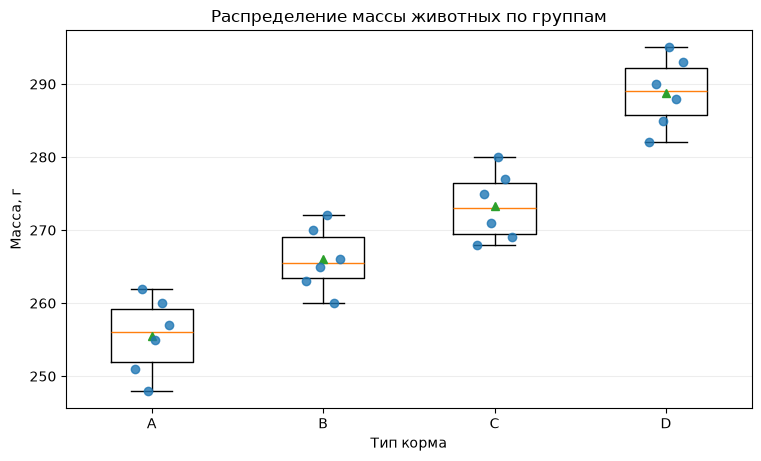

Группа A: среднее = 255.50 г, p-value Шапиро–Уилка = 0.879904
Группа B: среднее = 266.00 г, p-value Шапиро–Уилка = 0.916850
Группа C: среднее = 273.33 г, p-value Шапиро–Уилка = 0.648751
Группа D: среднее = 288.83 г, p-value Шапиро–Уилка = 0.941526
Левен: p-value = 0.941694
ANOVA: F = 49.924617, p-value = 1.79973e-09


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------


In [5]:
A = [251,262,248,255,260,257]
B = [263,270,265,272,260,266]
C = [268,275,271,280,277,269]
D = [282,290,285,295,288,293]

alpha = 0.05
groups = {"A": A, "B": B, "C": C, "D": D}
group_names = list(groups)
positions = np.arange(1, len(groups) + 1)

fig, ax = plt.subplots(figsize=(7.5, 4.5), layout="constrained")
ax.boxplot(list(groups.values()), positions=positions, widths=0.48, showmeans=True)
for position, measurements in zip(positions, groups.values()):
    offsets = np.linspace(-0.10, 0.10, len(measurements))
    ax.scatter(position + offsets, measurements, alpha=0.8, color="tab:blue", zorder=3)
ax.set_xticks(positions, group_names)
ax.set_xlabel("Тип корма")
ax.set_ylabel("Масса, г")
ax.set_title("Распределение массы животных по группам")
ax.grid(axis="y", alpha=0.22)
plt.show()

for name, measurements in groups.items():
    result = stats.shapiro(measurements)
    print(f"Группа {name}: среднее = {np.mean(measurements):.2f} г, "
          f"p-value Шапиро–Уилка = {result.pvalue:.6f}")
levene = stats.levene(*groups.values(), center="median")
anova = stats.f_oneway(*groups.values())
print(f"Левен: p-value = {levene.pvalue:.6f}")
print(f"ANOVA: F = {anova.statistic:.6f}, p-value = {anova.pvalue:.6g}")

if anova.pvalue < alpha:
    measurements = np.concatenate(list(groups.values()))
    labels = np.repeat(group_names, [len(values) for values in groups.values()])
    tukey = pairwise_tukeyhsd(measurements, labels, alpha=alpha)
    print(tukey.summary())

**Вывод.** Проверки Шапиро–Уилка и Левена не выявили нарушения допущений ANOVA при уровне 5%, а ANOVA показал различие средних (p ≈ 1,80 × 10⁻⁹). У корма D самая высокая средняя масса животных (288,83 г), и по Tukey HSD она значимо выше, чем у A, B и C.

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [6]:
conv_c, n_c = 85, 1000     # контроль
conv_v, n_v = 120, 1000    # тест

alpha = 0.05
p_c = conv_c / n_c
p_v = conv_v / n_v
wilson_c = proportion_confint(conv_c, n_c, alpha=alpha, method="wilson")
wilson_v = proportion_confint(conv_v, n_v, alpha=alpha, method="wilson")
z_statistic, p_value = proportions_ztest(
    [conv_v, conv_c], [n_v, n_c], alternative="two-sided"
)

np.random.seed(42)
n_bootstrap = 100_000
# Биномиальное число успехов эквивалентно пересэмплированию
# бинарных наблюдений с возвращением внутри каждой группы.
boot_v = np.random.binomial(n_v, p_v, size=n_bootstrap) / n_v
boot_c = np.random.binomial(n_c, p_c, size=n_bootstrap) / n_c
boot_low, boot_high = np.quantile(boot_v - boot_c, [alpha / 2, 1 - alpha / 2])

print(f"Контроль: {p_c:.1%}, 95%-й ДИ Уилсона [{wilson_c[0]:.2%}; {wilson_c[1]:.2%}]")
print(f"Тест: {p_v:.1%}, 95%-й ДИ Уилсона [{wilson_v[0]:.2%}; {wilson_v[1]:.2%}]")
print(f"Двусторонний z-тест: z = {z_statistic:.6f}, p-value = {p_value:.6f}")
print(f"Прирост конверсии: {(p_v - p_c) * 100:+.1f} п.п.")
print(f"95%-й бутстрэп-интервал для прироста: [{boot_low * 100:.1f}; {boot_high * 100:.1f}] п.п.")

Контроль: 8.5%, 95%-й ДИ Уилсона [6.93%; 10.39%]
Тест: 12.0%, 95%-й ДИ Уилсона [10.13%; 14.16%]
Двусторонний z-тест: z = 2.580322, p-value = 0.009871
Прирост конверсии: +3.5 п.п.
95%-й бутстрэп-интервал для прироста: [0.9; 6.2] п.п.


**Вывод.** Конверсия выросла с 8,5% до 12,0% (+3,5 п.п., p = 0,00987), а 95%-й бутстрэп-интервал для прироста целиком выше нуля. По конверсии тестовый вариант стоит выкатывать при корректной рандомизации и при условии, что другие важные метрики не ухудшились.